In [10]:
import pandas as pd
import numpy as np


df = pd.read_excel("C:/Users/Nitin/Downloads/Ecommerce_Sales_Optimized_Data.xlsx")

print("--- DATASET LOADED SUCCESSFULLY ---")
print(f"Total Rows: {len(df)}")
print(df.head())

--- DATASET LOADED SUCCESSFULLY ---
Total Rows: 578
    Order ID Customer ID  Order Date       City      Product Name  \
0  ORD-10001   CUST-1039  2026-06-15  Hyderabad  Wireless Earbuds   
1  ORD-10001   CUST-1039  2026-06-15  Hyderabad       Smart Watch   
2  ORD-10002   CUST-1030  2026-08-03      Delhi       Smart Watch   
3  ORD-10002   CUST-1030  2026-08-03      Delhi      Type-C Cable   
4  ORD-10003   CUST-1016  2026-08-01      Delhi       Smart Watch   

      Category  Quantity  Unit Price (INR)  Total Sales (INR)  
0  Electronics         1              1499               1499  
1  Electronics         1              2999               2999  
2  Electronics         1              2999               2999  
3  Accessories         1               299                299  
4  Electronics         1              2999               2999  


In [11]:
# Total Orders aur Unique Customers
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()

# Repeat Customer Calculation
orders_per_cust = df.groupby('Customer ID')['Order ID'].nunique()
repeat_customers = (orders_per_cust > 1).sum()
repeat_rate = (repeat_customers / total_customers) * 100

print("--- 1. PURCHASE PATTERNS & REPEAT CUSTOMERS ---")
print(f"Total Unique Customers : {total_customers}")
print(f"Total Unique Orders    : {total_orders}")
print(f"Repeat Customers Count : {repeat_customers}")
print(f"Repeat Customer Rate   : {repeat_rate:.1f}%")

--- 1. PURCHASE PATTERNS & REPEAT CUSTOMERS ---
Total Unique Customers : 50
Total Unique Orders    : 300
Repeat Customers Count : 48
Repeat Customer Rate   : 96.0%


In [12]:
from itertools import combinations
from collections import Counter

# Order ID ke against products ki list banana
order_baskets = df.groupby('Order ID')['Product Name'].apply(lambda x: list(set(x)))

pair_counts = Counter()
item_counts = Counter()
total_orders_count = len(order_baskets)

for items in order_baskets:
    for item in items:
        item_counts[item] += 1
    for pair in combinations(sorted(items), 2):
        pair_counts[pair] += 1

rules = []
for (itemA, itemB), count in pair_counts.items():
    conf_A_B = count / item_counts[itemA]
    lift_A_B = conf_A_B / (item_counts[itemB] / total_orders_count)
    rules.append({'If Customer Buys': itemA, 'Recommend': itemB, 'Frequency': count, 'Confidence (%)': f"{conf_A_B*100:.1f}%", 'Lift': round(lift_A_B, 2)})
    
    conf_B_A = count / item_counts[itemB]
    lift_B_A = conf_B_A / (item_counts[itemA] / total_orders_count)
    rules.append({'If Customer Buys': itemB, 'Recommend': itemA, 'Frequency': count, 'Confidence (%)': f"{conf_B_A*100:.1f}%", 'Lift': round(lift_B_A, 2)})

rules_df = pd.DataFrame(rules).sort_values(by='Lift', ascending=False)

print("--- 2. MARKET BASKET ANALYSIS & PRODUCT AFFINITY ---")
print(rules_df.head(5).to_string(index=False))

--- 2. MARKET BASKET ANALYSIS & PRODUCT AFFINITY ---
   If Customer Buys           Recommend  Frequency Confidence (%)  Lift
       Gaming Mouse Mechanical Keyboard         33          47.1%  2.24
Mechanical Keyboard        Gaming Mouse         33          52.4%  2.24
   Wireless Earbuds         Smart Watch         26          36.6%  2.03
        Smart Watch    Wireless Earbuds         26          48.1%  2.03
       Type-C Cable       Laptop Sleeve         26          28.3%  1.84


In [13]:
# Total Revenue aur AOV Calculation
total_revenue = df['Total Sales (INR)'].sum()
aov = total_revenue / total_orders

print("--- 3. OUTCOME: CROSS-SELLING & AOV ---")
print(f"Total Revenue             : ₹{total_revenue:,.2f}")
print(f"Average Order Value (AOV) : ₹{aov:,.2f}")

--- 3. OUTCOME: CROSS-SELLING & AOV ---
Total Revenue             : ₹917,386.00
Average Order Value (AOV) : ₹3,057.95


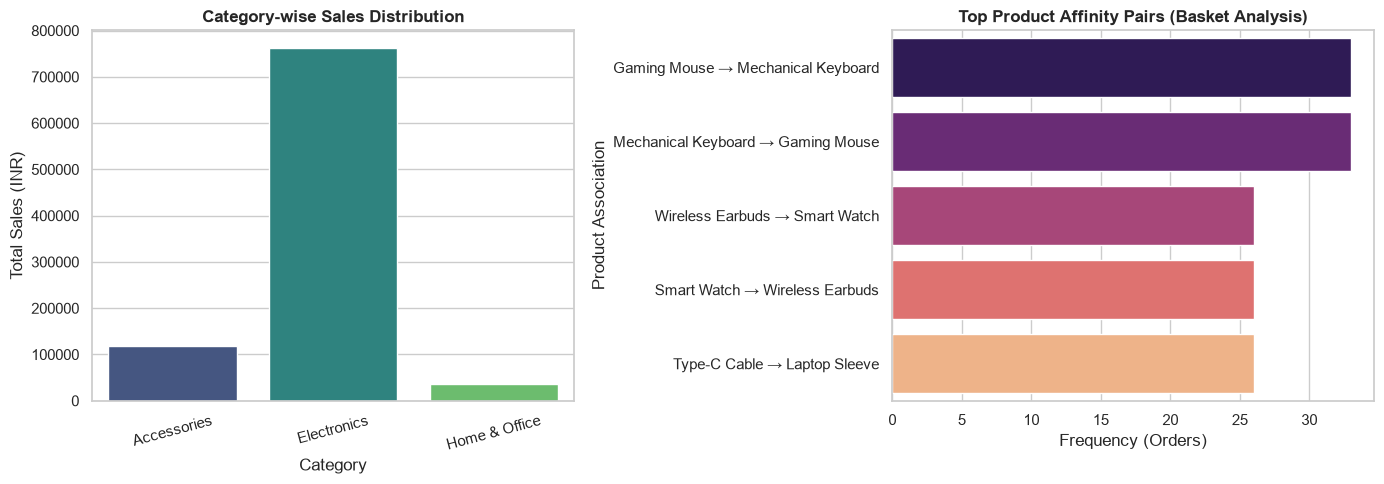

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Category-wise Sales Distribution (Updated with hue & legend=False)
category_sales = df.groupby('Category')['Total Sales (INR)'].sum().reset_index()
sns.barplot(ax=axes[0], x='Category', y='Total Sales (INR)', data=category_sales, hue='Category', palette='viridis', legend=False)
axes[0].set_title('Category-wise Sales Distribution', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)

# Graph 2: Top Product Association Pairs (Updated with hue & legend=False)
top_pairs = rules_df.head(5).copy()
top_pairs['Pair'] = top_pairs['If Customer Buys'] + ' → ' + top_pairs['Recommend']
sns.barplot(ax=axes[1], x='Frequency', y='Pair', data=top_pairs, hue='Pair', palette='magma', legend=False)
axes[1].set_title('Top Product Affinity Pairs (Basket Analysis)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Frequency (Orders)')
axes[1].set_ylabel('Product Association')

plt.tight_layout()
plt.show()

In [16]:
# --- DATA-DRIVEN RECOMMENDATION & AOV IMPACT ---
print("=== BUSINESS RECOMMENDATION FOR AOV GROWTH ===")
print(f"Current Average Order Value (AOV): ₹{aov:,.2f}")
print("Strategy: By implementing cross-selling based on top product pairs")
print("(e.g., recommending Mechanical Keyboard when a customer buys a Gaming Mouse),")
print("the platform can successfully bundle items, increase basket size, and boost AOV.")

=== BUSINESS RECOMMENDATION FOR AOV GROWTH ===
Current Average Order Value (AOV): ₹3,057.95
Strategy: By implementing cross-selling based on top product pairs
(e.g., recommending Mechanical Keyboard when a customer buys a Gaming Mouse),
the platform can successfully bundle items, increase basket size, and boost AOV.
